In [ ]:
# アンサンブル法
# 複数の機械学習モデルを組み合わせることで、より強力なモデルを構築する手法

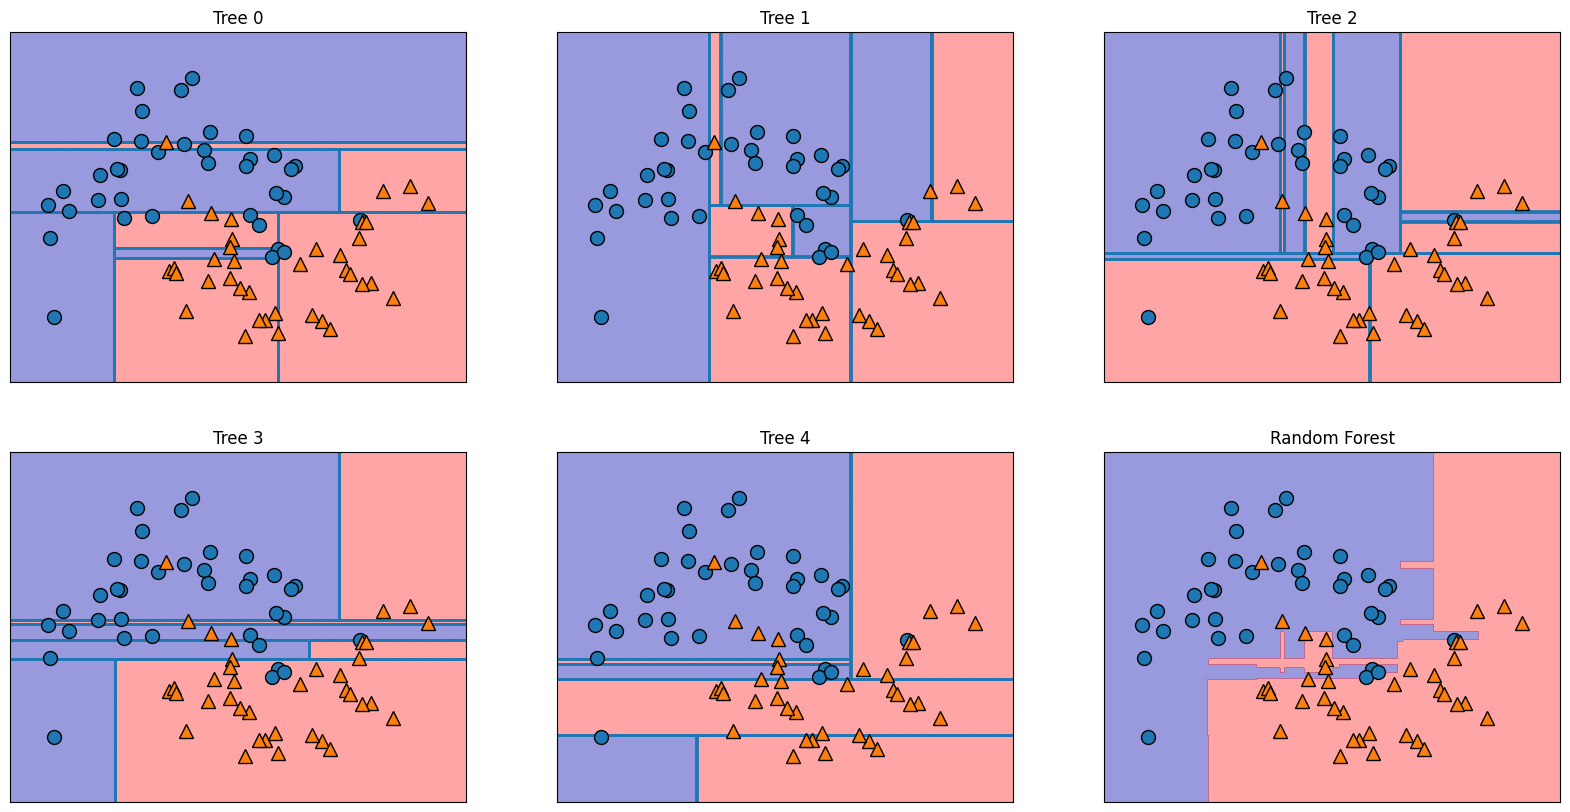

In [5]:
# ランダムフォレスト
# それぞれ異なった方向に過剰適合した決定木をたくさん作り、平均を取ることで過剰適合の度合いを減らすことができる

# ブートストラップサンプリング
# 例） ['a', 'b', 'c', 'd'] → ['b', 'd', 'd', 'c'] のようにデータポイントを選び出す
# 分岐させるときに、特徴量から max_features 個の特徴量ランダムで選ぶと、決定木自体にランダム性が生まれる

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import mglearn

X, y = make_moons(n_samples=100, noise=0.25, random_state=3)
X_train, X_test, y_train, y_test = train_test_split(X, y, stratify=y, random_state=42)

forest = RandomForestClassifier(n_estimators=5, random_state=2)
forest.fit(X_train, y_train)

forest = RandomForestClassifier(n_estimators=5, random_state=2)
forest.fit(X_train, y_train)

fig, axes = plt.subplots(2, 3, figsize=(20, 10))
for i, (ax, tree) in enumerate(zip(axes.ravel(), forest.estimators_)):
    ax.set_title("Tree {}".format(i))
    mglearn.plots.plot_tree_partition(X_train, y_train, tree, ax=ax)

mglearn.plots.plot_2d_separator(forest, X_train, fill=True, ax=axes[-1, -1], alpha=.4)
axes[-1, -1].set_title("Random Forest")
mglearn.discrete_scatter(X_train[:, 0], X_train[:, 1], y_train)

In [8]:
from sklearn.datasets import load_breast_cancer

cancer = load_breast_cancer()
X_train, X_test, y_train, y_test = train_test_split(
    cancer.data, cancer.target, random_state=0)
forest = RandomForestClassifier(n_estimators=100, random_state=0) # 決定木を100個作成
forest.fit(X_train, y_train)

print("Accuracy on training set: {:.3f}".format(forest.score(X_train, y_train)))
print("Accuracy on test set: {:.3f}".format(forest.score(X_test, y_test)))
print(forest.max_features) # 特徴量の数の1/2乗にデフォルトで設定されている

Accuracy on training set: 1.000
Accuracy on test set: 0.972
sqrt


Text(0, 0.5, 'Feature')

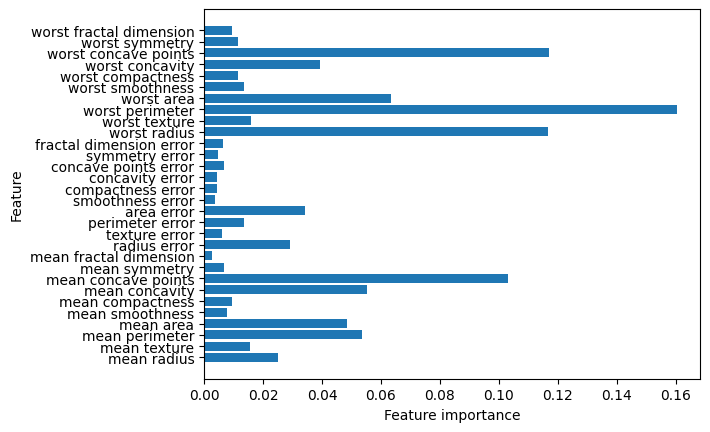

In [16]:
import numpy as np

n_features = cancer.data.shape[1]
plt.barh(range(n_features), forest.feature_importances_, align='center')
plt.yticks(np.arange(n_features), cancer.feature_names)
plt.xlabel("Feature importance")
plt.ylabel("Feature")

In [19]:
# 勾配ブースティング回帰木
# 1つ前の決定木の誤りを、次の決定木が修正するようにして、決定木を順番に作っていく
# 弱学習機（深さ1~5の浅い決定木のような、簡単なモデル）を多数組み合わせることにより構築する

from sklearn.ensemble import GradientBoostingClassifier

X_train, X_test, y_train, y_test = train_test_split(
    cancer.data, cancer.target, random_state=0)

gbrt = GradientBoostingClassifier(random_state=0)
gbrt.fit(X_train, y_train)
print("Accuracy on training set: {:.3f}".format(gbrt.score(X_train, y_train)))
print("Accuracy on test set: {:.3f}".format(gbrt.score(X_test, y_test)))

# 深さ1にして、過剰適合を回避してみる
gbrt = GradientBoostingClassifier(random_state=0, max_depth=1)
gbrt.fit(X_train, y_train)
print("Accuracy on training set: {:.3f}".format(gbrt.score(X_train, y_train)))
print("Accuracy on test set: {:.3f}".format(gbrt.score(X_test, y_test)))

# 学習率を下げて、過剰適合を回避してみる
gbrt = GradientBoostingClassifier(random_state=0, learning_rate=0.01)
gbrt.fit(X_train, y_train)
print("Accuracy on training set: {:.3f}".format(gbrt.score(X_train, y_train)))
print("Accuracy on test set: {:.3f}".format(gbrt.score(X_test, y_test)))

Accuracy on training set: 1.000
Accuracy on test set: 0.965
Accuracy on training set: 0.991
Accuracy on test set: 0.972
Accuracy on training set: 0.988
Accuracy on test set: 0.958


Text(0, 0.5, 'Feature')

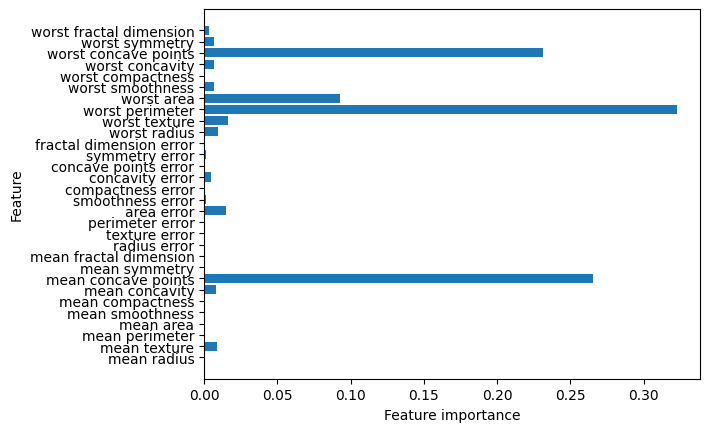

In [22]:
gbrt = GradientBoostingClassifier(random_state=0, max_depth=1)
gbrt.fit(X_train, y_train)

# ランダムフォレストの方が、マイナーな特徴量を拾いやすいが、処理速度が遅い
n_features = cancer.data.shape[1]
plt.barh(range(n_features), gbrt.feature_importances_, align='center')
plt.yticks(np.arange(n_features), cancer.feature_names)
plt.xlabel("Feature importance")
plt.ylabel("Feature")